# 05 — OOF Calibration, Threshold Selection, Locked Test (`2014J`) Audit & Subgroup Fairness (`P1-B5`)

- **Phase A (LOCKED):** Explicit `StratifiedKFold(5)` OOF calibration (`FrozenEstimator`) + threshold `tau*` (with transparent fallback if `Precision >= 0.70` is unattainable) strictly on `val_calib (40% of 2014B)`.
- **Phase B (FROZEN HISTORICAL `2014J` ARTIFACT):** The `2014J` evaluation report was committed in `P1-B5` (`2c8bab8`) and has remained unchanged across subsequent Git history. To preserve strict holdout discipline (`FA-02`, `AUD-B6-06`), this notebook performs a **read-only audit & visualization** of the frozen artifacts in `reports/` without re-executing `2014J`.
- *(For opt-in isolated post-hoc historical reproduction into a separate directory, run `python -m oulad.run_all --skip-download --include-locked-test --reports-dir ./tmp_repro/reports --figures-dir ./tmp_repro/figures`.)*

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from oulad.config import FIGURES_DIR, REPORTS_DIR

locked_report = json.loads((REPORTS_DIR / "metrics_test_locked.json").read_text(encoding="utf-8"))
proto = locked_report["evaluation_protocol"]
assert proto["single_unlock_discipline"] is True
assert proto["post_unlock_model_edits"] == 0

print("Champion selected on val_select:", proto["champion_selected_on_val_select"])
print(
    f"val_calib positive rate: {proto['val_calib_positive_rate']:.4f} | "
    f"2014J positive rate: {proto['test_positive_rate']:.4f} (n={proto['n_test_2014j']})"
)

print("\n=== Phase A: 5-Fold OOF Calibration & Threshold Selection (val_calib) ===")
oof_rows = []
for model_name, info in locked_report["oof_calibration_val_calib"].items():
    cand = info["candidate_oof_metrics"]
    th = info["threshold_selection_oof"]
    oof_rows.append(
        {
            "model": model_name,
            "n_calib": info["n_calib"],
            "isotonic_blocked": info["isotonic_blocked"],
            "oof_brier_uncal": cand["uncalibrated"]["brier_score"],
            "oof_brier_sigmoid": cand["sigmoid"]["brier_score"],
            "oof_brier_isotonic": cand.get("isotonic", {}).get("brier_score"),
            "chosen_method": info["chosen_method"],
            "locked_tau": th["threshold"],
            "oof_precision": th["oof_precision"],
            "oof_recall": th["oof_recall"],
        }
    )
display(pd.DataFrame(oof_rows))

print("\n=== Phase B: Locked Test 2014J — 3 Primary Models (T=28 Operational) ===")
test_rows = []
for model_name, info in locked_report["models_test_locked_2014j_t28"].items():
    raw_m = info["uncalibrated_raw"]
    fin_m = info["calibrated_or_final"]
    test_rows.append(
        {
            "model": model_name,
            "calibration_method": info["calibration_method"],
            "tau*": info["locked_threshold"],
            "pr_auc": fin_m["pr_auc"],
            "roc_auc": fin_m["roc_auc"],
            "raw_brier": raw_m["brier_score"],
            "final_brier": fin_m["brier_score"],
            "raw_ece": raw_m["ece_10bins"],
            "final_ece": fin_m["ece_10bins"],
            "precision": fin_m["precision"],
            "recall": fin_m["recall"],
            "f1": fin_m["f1"],
        }
    )
display(pd.DataFrame(test_rows))

Champion selected on val_select: lightgbm
val_calib positive rate: 0.4843 | 2014J positive rate: 0.4079 (n=9213)

=== Phase A: 5-Fold OOF Calibration & Threshold Selection (val_calib) ===


,model,n_calib,isotonic_blocked,oof_brier_uncal,oof_brier_sigmoid,oof_brier_isotonic,chosen_method,locked_tau,oof_precision,oof_recall
0,logistic_regression,2604,False,0.18093,0.18006,0.18059,sigmoid,0.4398,0.7000,0.7272
1,lightgbm,2604,False,0.17912,0.18011,0.18064,uncalibrated,0.4279,0.7011,0.7328
2,tabular_mlp,2604,False,0.18535,0.18424,0.18429,sigmoid,0.4156,0.7004,0.7137



=== Phase B: Locked Test 2014J — 3 Primary Models (T=28 Operational) ===


,model,calibration_method,tau*,pr_auc,roc_auc,raw_brier,final_brier,raw_ece,final_ece,precision,recall,f1
0,logistic_regression,sigmoid,0.4398,0.6184,0.7239,0.2180,0.2187,0.0814,0.0812,0.6132,0.6437,0.6281
1,lightgbm,uncalibrated,0.4279,0.6813,0.7467,0.2040,0.2040,0.0542,0.0542,0.6023,0.6852,0.6411
2,tabular_mlp,sigmoid,0.4156,0.6376,0.7221,0.2128,0.2186,0.0532,0.0713,0.6022,0.6408,0.6209


In [2]:
print("=== Cutoff Horizon Comparison on Locked Test 2014J ===")
display(pd.read_csv(REPORTS_DIR / "cutoff_comparison_test.csv"))

print(
    "\n=== Illustrative Cost-Benefit Table "
    "(Assumptions Only; Non-Bayes for Uncalibrated Scores) ==="
)
cb_cols = [
    "cost_ratio_fp_to_fn",
    "policy",
    "threshold",
    "fp",
    "fn",
    "total_illustrative_cost",
    "cost_per_student",
]
display(pd.DataFrame(locked_report["illustrative_cost_benefit_2014j"])[cb_cols])

err = locked_report["post_lock_error_analysis_2014j"]
print(
    f"\n=== Post-Lock Error Audit (min(20, len)) ===\n"
    f"FP: sampled {err['sampled_fp_count']} / {err['total_fp']} total | "
    f"FN: sampled {err['sampled_fn_count']} / {err['total_fn']} total"
)

=== Cutoff Horizon Comparison on Locked Test 2014J ===


,mode,cutoff,model,n_test_2014j,n_features,positive_rate,pr_auc,roc_auc,brier_score
0,operational,14,logistic_regression,9332,35,0.4165,0.6137,0.7049,0.2152
1,operational,14,lightgbm,9332,35,0.4165,0.6312,0.7053,0.2127
2,operational,21,logistic_regression,9291,36,0.4130,0.6110,0.7120,0.2224
3,operational,21,lightgbm,9291,36,0.4130,0.6526,0.7205,0.2148
4,operational,28,logistic_regression,9213,37,0.4079,0.6184,0.7239,0.2180
5,operational,28,lightgbm,9213,37,0.4079,0.6813,0.7467,0.2040
6,common,14,logistic_regression,9192,35,0.4076,0.6070,0.7050,0.2136
7,common,14,lightgbm,9192,35,0.4076,0.6239,0.7058,0.2109
8,common,21,logistic_regression,9192,36,0.4076,0.6009,0.7103,0.2218
9,common,21,lightgbm,9192,36,0.4076,0.6501,0.7227,0.2125



=== Illustrative Cost-Benefit Table (Assumptions Only; Non-Bayes for Uncalibrated Scores) ===


,cost_ratio_fp_to_fn,policy,threshold,fp,fn,total_illustrative_cost,cost_per_student
0,1:5,locked_tau,0.4279,1700,1183,7615,0.8265
1,1:5,bayes_cost_tau,0.1667,4216,180,5116,0.5553
2,1:10,locked_tau,0.4279,1700,1183,13530,1.4686
3,1:10,bayes_cost_tau,0.0909,5247,12,5367,0.5825



=== Post-Lock Error Audit (min(20, len)) ===
FP: sampled 20 / 1700 total | FN: sampled 20 / 1183 total


=== 18-Subgroup Performance Audit on Locked Test 2014J (Not a Fairness Certification) ===


,group_col,group_value,n,n_pos,positive_rate,recall,precision,fpr,low_sample_warning
0,gender,F,3872,1490,0.3848,0.6161,0.5334,0.3371,False
1,gender,M,5341,2268,0.4246,0.7306,0.6488,0.2919,False
2,disability,N,8358,3307,0.3957,0.6734,0.5896,0.3069,False
3,disability,Y,855,451,0.5275,0.7716,0.6988,0.3713,False
4,imd_band,0-10%,820,404,0.4927,0.7376,0.6221,0.4351,False
5,imd_band,10-20,912,434,0.4759,0.7604,0.6574,0.3598,False
6,imd_band,20-30%,973,447,0.4594,0.7360,0.6489,0.3384,False
7,imd_band,30-40%,980,408,0.4163,0.7059,0.6115,0.3199,False
8,imd_band,40-50%,925,379,0.4097,0.6649,0.5860,0.3260,False
9,imd_band,50-60%,921,372,0.4039,0.6909,0.5788,0.3406,False


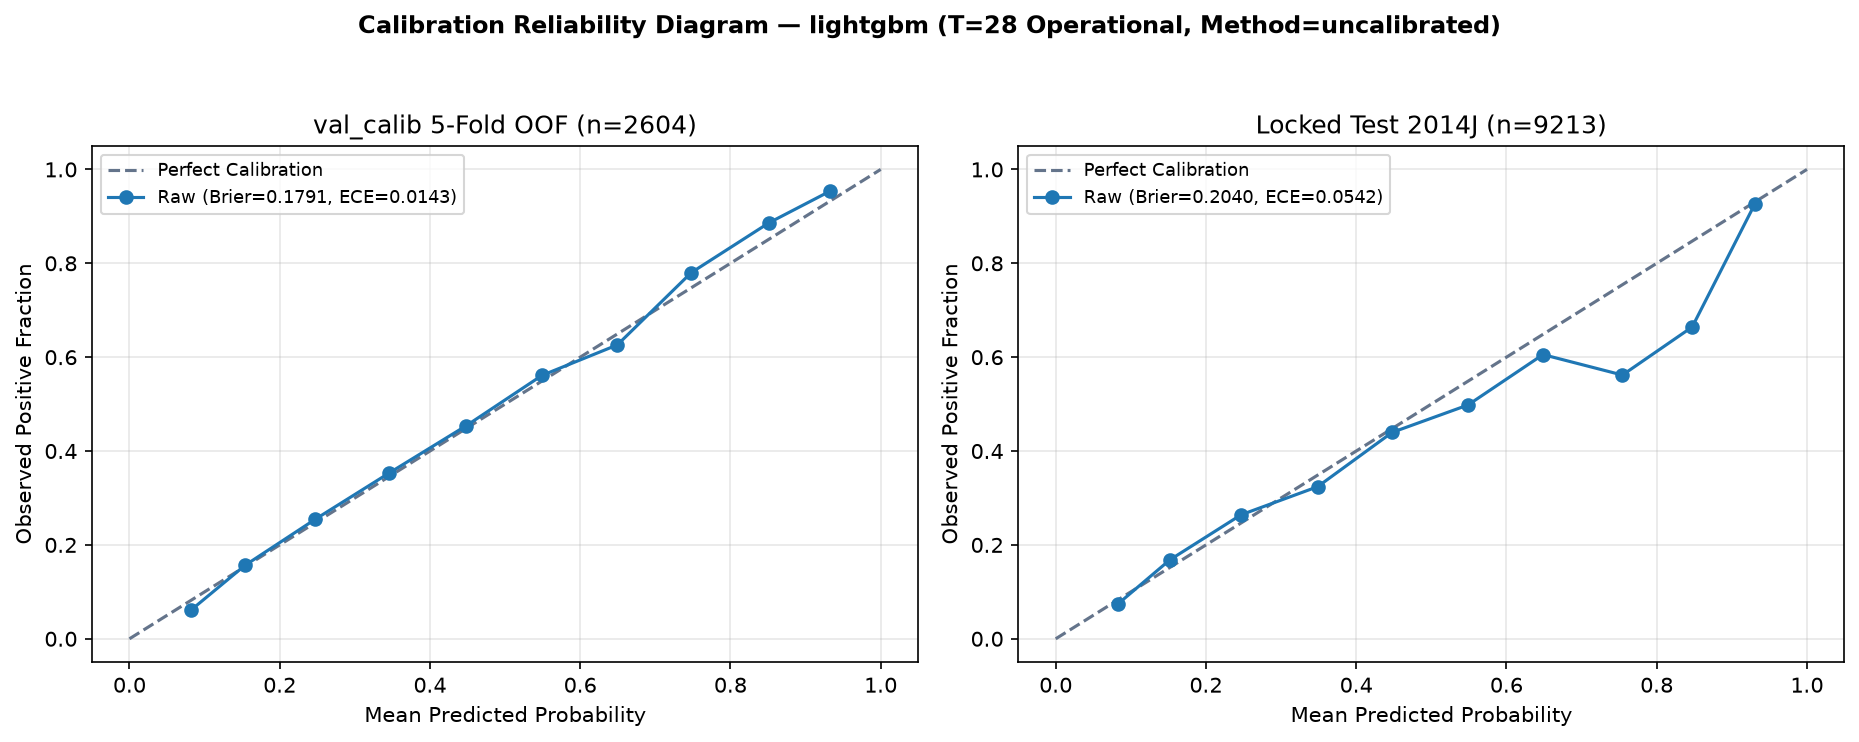

In [3]:
print("=== 18-Subgroup Performance Audit on Locked Test 2014J (Not a Fairness Certification) ===")
display(pd.read_csv(REPORTS_DIR / "fairness_test.csv"))
display(Image(filename=str(FIGURES_DIR / "calibration_curve.png")))